# W13. Systemy adaptacyjne HCI i XR

**Wersja źródła:** 1.2.4 · **Data:** 2026-11-04

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(13)
poziom, sprawnosc, sesje = 3, 4.2, 30
wysoki, niski = .85, .55
historia = []


In [2]:
def decyzja(poziom,trafnosc):
    if trafnosc>=wysoki: return min(7,poziom+1)
    if trafnosc<niski: return max(1,poziom-1)
    return poziom

def decyzja_stabilna(poziom,oceny,nr,ostatnia_zmiana):
    if len(oceny)<3 or nr-ostatnia_zmiana<3: return poziom
    return decyzja(poziom,np.mean(oceny[-3:]))
assert decyzja(7,1.0)==7 and decyzja(1,0.0)==1


In [3]:
losowania = rng.random((sesje,20))
historie = {}
for wariant in ("bazowy","stabilny"):
    poziom, ostatnia, oceny, przebieg = 3, -10, [], []
    for nr, losy in enumerate(losowania, 1):
        p = np.clip(.71 + .09*(sprawnosc-poziom), .1, .97)
        oceny.append(np.mean(losy < p))
        nowy = (decyzja(poziom,oceny[-1]) if wariant=="bazowy"
                else decyzja_stabilna(poziom,oceny,nr,ostatnia))
        przebieg.append((nr,poziom,oceny[-1],nowy))
        if nowy != poziom: ostatnia = nr
        poziom = nowy
    historie[wariant] = np.array(przebieg)
historia = historie["bazowy"]


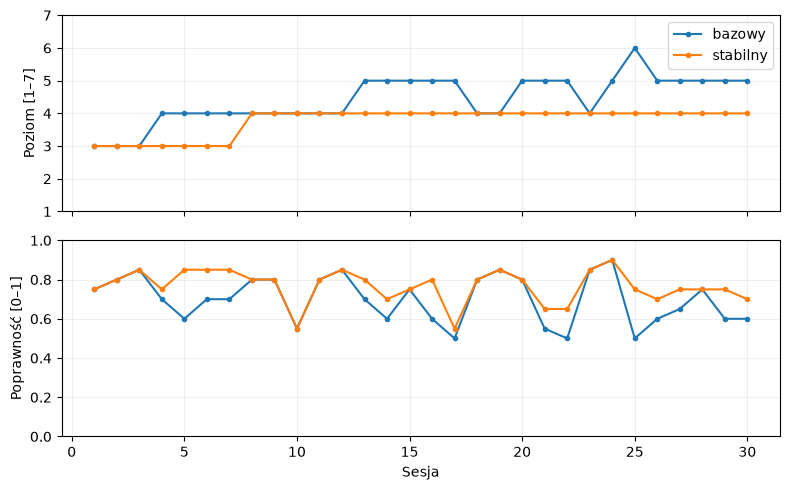

bazowy zmiany: 8 poprawność: 0.7
stabilny zmiany: 1 poprawność: 0.767


In [4]:
fig,ax=plt.subplots(2,1,figsize=(8,5),sharex=True)
for wariant,h in historie.items():
    ax[0].plot(h[:,0],h[:,1],marker=".",label=wariant)
    ax[1].plot(h[:,0],h[:,2],marker=".",label=wariant)
ax[0].set(ylabel="Poziom [1–7]",ylim=(1,7))
ax[1].set(xlabel="Sesja",ylabel="Poprawność [0–1]",ylim=(0,1))
ax[0].legend()
for a in ax:a.grid(alpha=.2)
plt.tight_layout();plt.show()
for wariant,h in historie.items():
    print(wariant, "zmiany:", int(sum(h[:,1]!=h[:,3])),
          "poprawność:", round(np.mean(h[:,2]),3))
